In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture

OUTPUT = Path("clv_outputs")
OUTPUT.mkdir(exist_ok=True)

# Supports either of the common project folder structures
paths = [
    Path("data/final_invoice_level.csv"),
    Path("final_invoice_level.csv")
]

data_path = next((p for p in paths if p.exists()), None)

if data_path is None:
    raise FileNotFoundError("Cannot find final_invoice_level.csv")

invoices = pd.read_csv(
    data_path,
    parse_dates=["InvoiceDate"]
)

invoices = invoices[
    invoices["InvoiceAmount"] > 0
].copy()

print("Dataset shape:", invoices.shape)
print("Unique customers:", invoices["CustomerID"].nunique())


Dataset shape: (36594, 13)
Unique customers: 5852


In [2]:

# Customers with at least one recorded purchase during 2010
cohort = np.sort(
    invoices.loc[
        (invoices["InvoiceDate"] >= "2010-01-01") &
        (invoices["InvoiceDate"] < "2011-01-01"),
        "CustomerID"
    ].unique()
)

# Historical period used to fit the CLV model
train = invoices[
    invoices["CustomerID"].isin(cohort) &
    (invoices["InvoiceDate"] >= "2011-01-01") &
    (invoices["InvoiceDate"] < "2011-09-01")
].copy()

# Future period used to evaluate predictions
test = invoices[
    invoices["CustomerID"].isin(cohort) &
    (invoices["InvoiceDate"] >= "2011-09-01") &
    (invoices["InvoiceDate"] < "2011-12-01")
].copy()

TRAIN_MONTHS = 8
FORECAST_MONTHS = 3

print("Customers in cohort:", len(cohort))
print("Training invoices:", len(train))
print("Testing invoices:", len(test))


Customers in cohort: 4205
Training invoices: 8068
Testing invoices: 4426


In [3]:

training_summary = train.groupby("CustomerID").agg(
    TrainCount=("InvoiceNo", "nunique"),
    TrainRevenue=("InvoiceAmount", "sum"),
    AvgInvoice=("InvoiceAmount", "mean")
).reset_index()

# Include customers with no purchases in training
customers = pd.DataFrame({
    "CustomerID": cohort
})

customers = customers.merge(
    training_summary,
    on="CustomerID",
    how="left"
)

customers[
    ["TrainCount", "TrainRevenue", "AvgInvoice"]
] = customers[
    ["TrainCount", "TrainRevenue", "AvgInvoice"]
].fillna(0)

print("Total customers:", len(customers))
print(
    "Customers with zero training purchases:",
    (customers["TrainCount"] == 0).sum()
)

display(customers.head())


Total customers: 4205
Customers with zero training purchases: 2009


,CustomerID,TrainCount,TrainRevenue,AvgInvoice
0,12346,1.0,77183.60,77183.6000
1,12347,4.0,2079.07,519.7675
2,12348,2.0,514.44,257.2200
3,12349,0.0,0.00,0.0000
4,12351,0.0,0.00,0.0000


In [4]:

# Same transformed variables as the uploaded notebook
X = np.log1p(
    customers[["TrainCount", "AvgInvoice"]].to_numpy()
)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Refit the same type of mixture using training data only
gmm = GaussianMixture(
    n_components=9,
    covariance_type="full",
    random_state=42,
    n_init=5,
    max_iter=500,
    reg_covar=1e-5
)

gmm.fit(X_scaled)

# Probability of belonging to each group
membership = gmm.predict_proba(X_scaled)

customers["Segment"] = membership.argmax(axis=1)

print("Number of groups:", gmm.n_components)
print("Membership shape:", membership.shape)

print("\nCustomers per group:")
print(customers["Segment"].value_counts().sort_index())


c:\Users\aroy3\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\aroy3\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\aroy3\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\aroy3\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

Number of groups: 9
Membership shape: (4205, 9)

Customers per group:
Segment
0      46
1    2009
2     185
3      49
4     164
5     422
6     295
7     766
8     269
Name: count, dtype: int64


In [5]:

# Calculate log invoice amounts
log_data = train[
    ["CustomerID", "InvoiceAmount"]
].copy()

log_data["LogAmount"] = np.log(
    log_data["InvoiceAmount"]
)

log_data["LogAmountSq"] = (
    log_data["LogAmount"] ** 2
)

# Summarise log amounts by customer
log_summary = log_data.groupby("CustomerID").agg(
    SumLog=("LogAmount", "sum"),
    SumLogSq=("LogAmountSq", "sum")
).reset_index()

customers = customers.merge(
    log_summary,
    on="CustomerID",
    how="left"
)

customers[["SumLog", "SumLogSq"]] = (
    customers[["SumLog", "SumLogSq"]].fillna(0)
)

counts = customers["TrainCount"].to_numpy()

# Weighted customer and invoice counts
group_weights = membership.sum(axis=0)
group_counts = membership.T @ counts

# Monthly Poisson purchase rates
lambdas = group_counts / (
    TRAIN_MONTHS * group_weights
)

# Calculate Lognormal parameters
valid = group_counts > 1e-8
denominator = np.maximum(group_counts, 1e-12)

mu = (
    membership.T @ customers["SumLog"].to_numpy()
) / denominator

log_variance = (
    membership.T @ customers["SumLogSq"].to_numpy()
) / denominator - mu**2

log_variance = np.maximum(log_variance, 0)

sigma = np.sqrt(log_variance)

# Expected invoice amounts
mean_invoice = np.zeros(gmm.n_components)

mean_invoice[valid] = np.exp(
    mu[valid] + log_variance[valid] / 2
)

# Expected revenue over 3 months in each group
group_clv = (
    FORECAST_MONTHS * lambdas * mean_invoice
)

group_results = pd.DataFrame({
    "Segment": np.arange(gmm.n_components),
    "MonthlyPurchaseRate": lambdas,
    "LognormalMu": np.where(valid, mu, np.nan),
    "LognormalSigma": np.where(valid, sigma, np.nan),
    "ExpectedInvoiceAmount": np.where(
        valid, mean_invoice, np.nan
    ),
    "Expected3MRevenue": group_clv
})

display(group_results.round(2))


,Segment,MonthlyPurchaseRate,LognormalMu,LognormalSigma,ExpectedInvoiceAmount,Expected3MRevenue
0,0,0.12,5.64,1.62,1056.98,396.37
1,1,0.00,NaN,NaN,NaN,0.00
2,2,0.50,5.54,1.02,426.87,640.30
3,3,3.03,5.74,1.52,983.97,8943.63
4,4,1.29,5.55,0.91,389.62,1511.88
5,5,0.25,5.51,0.94,381.35,286.01
6,6,0.38,5.62,0.93,424.27,477.31
7,7,0.13,5.51,0.63,301.97,113.24
8,8,0.73,5.53,0.98,408.72,892.49


In [6]:

# Multiply group CLV values by membership probabilities
customers["Predicted3MRevenue"] = (
    membership @ group_clv
)

display(
    customers[[
        "CustomerID",
        "Segment",
        "TrainCount",
        "Predicted3MRevenue"
    ]].head(10).round(2)
)

print(
    "Total predicted 3-month revenue:",
    round(customers["Predicted3MRevenue"].sum(), 2)
)


,CustomerID,Segment,TrainCount,Predicted3MRevenue
0,12346,0,1.0,396.42
1,12347,2,4.0,642.06
2,12348,5,2.0,286.07
3,12349,1,0.0,0.00
4,12351,1,0.0,0.00
5,12352,2,4.0,641.69
6,12353,7,1.0,156.06
7,12355,7,1.0,138.36
8,12356,5,2.0,286.51
9,12357,1,0.0,0.00


Total predicted 3-month revenue: 1554400.42


In [7]:

# Actual future spending
actual = test.groupby("CustomerID").agg(
    Actual3MRevenue=("InvoiceAmount", "sum")
).reset_index()

customers = customers.merge(
    actual,
    on="CustomerID",
    how="left"
)

customers["Actual3MRevenue"] = (
    customers["Actual3MRevenue"].fillna(0)
)

print(
    "Total actual 3-month revenue:",
    round(customers["Actual3MRevenue"].sum(), 2)
)

print(
    "Customers without purchases in test period:",
    (customers["Actual3MRevenue"] == 0).sum()
)

display(
    customers[[
        "CustomerID",
        "Predicted3MRevenue",
        "Actual3MRevenue"
    ]].head(10).round(2)
)


Total actual 3-month revenue: 2399052.4
Customers without purchases in test period: 2374


,CustomerID,Predicted3MRevenue,Actual3MRevenue
0,12346,396.42,0.00
1,12347,642.06,1294.32
2,12348,286.07,270.00
3,12349,0.00,1457.55
4,12351,0.00,0.00
5,12352,641.69,744.23
6,12353,156.06,0.00
7,12355,138.36,0.00
8,12356,286.51,58.35
9,12357,0.00,6207.67


In [8]:

# One-group baseline estimated using training data
log_amounts = np.log(train["InvoiceAmount"])

baseline_lambda = (
    len(train) / (len(customers) * TRAIN_MONTHS)
)

baseline_mean_invoice = np.exp(
    log_amounts.mean() + log_amounts.var(ddof=0) / 2
)

baseline_clv = (
    FORECAST_MONTHS *
    baseline_lambda *
    baseline_mean_invoice
)

actual_values = customers["Actual3MRevenue"].to_numpy()
group_predictions = customers["Predicted3MRevenue"].to_numpy()

baseline_predictions = np.full(
    len(customers), baseline_clv
)

def evaluate_model(name, predictions):
    errors = predictions - actual_values

    return {
        "Model": name,
        "MAE": np.mean(np.abs(errors)),
        "RMSE": np.sqrt(np.mean(errors**2)),
        "PredictedTotal": predictions.sum(),
        "ActualTotal": actual_values.sum()
    }

evaluation = pd.DataFrame([
    evaluate_model("One-Group Baseline", baseline_predictions),
    evaluate_model("Group-Based CLV", group_predictions)
])

display(evaluation.round(2))


,Model,MAE,RMSE,PredictedTotal,ActualTotal
0,One-Group Baseline,651.42,3377.92,1432338.72,2399052.4
1,Group-Based CLV,466.47,2949.57,1554400.42,2399052.4


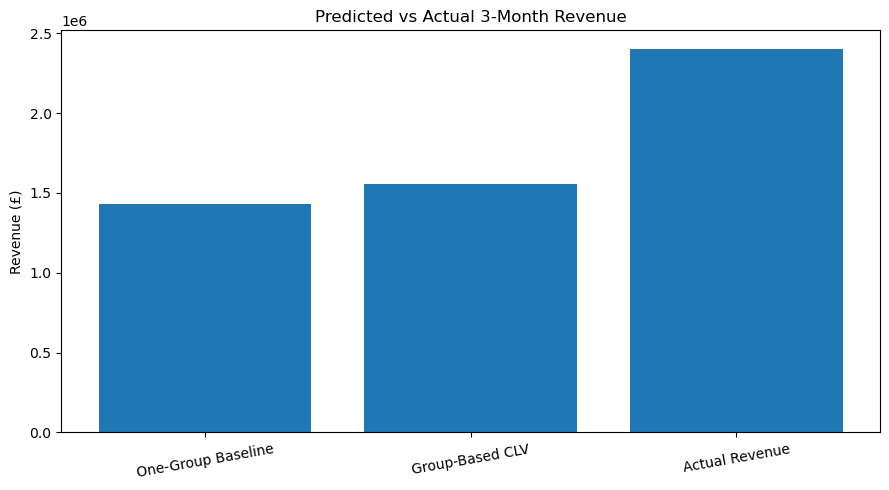

In [9]:

labels = [
    "One-Group Baseline",
    "Group-Based CLV",
    "Actual Revenue"
]

values = [
    baseline_predictions.sum(),
    group_predictions.sum(),
    actual_values.sum()
]

plt.figure(figsize=(9, 5))

plt.bar(labels, values)

plt.title("Predicted vs Actual 3-Month Revenue")
plt.ylabel("Revenue (£)")

plt.xticks(rotation=10)
plt.tight_layout()

plt.savefig(
    OUTPUT / "clv_predicted_vs_actual.png",
    dpi=300
)

plt.show()


In [10]:

# Save customer-level CLV forecasts
customers[[
    "CustomerID",
    "Segment",
    "TrainCount",
    "TrainRevenue",
    "Predicted3MRevenue",
    "Actual3MRevenue"
]].to_csv(
    OUTPUT / "customer_clv_predictions.csv",
    index=False
)

# Save group parameters
group_results.to_csv(
    OUTPUT / "clv_group_parameters.csv",
    index=False
)

# Save accuracy measures
evaluation.to_csv(
    OUTPUT / "clv_model_evaluation.csv",
    index=False
)

print("CLV analysis completed!")
print("Results saved in:", OUTPUT.resolve())


CLV analysis completed!
Results saved in: C:\Users\aroy3\Downloads\Online_retail_project\clv_outputs
